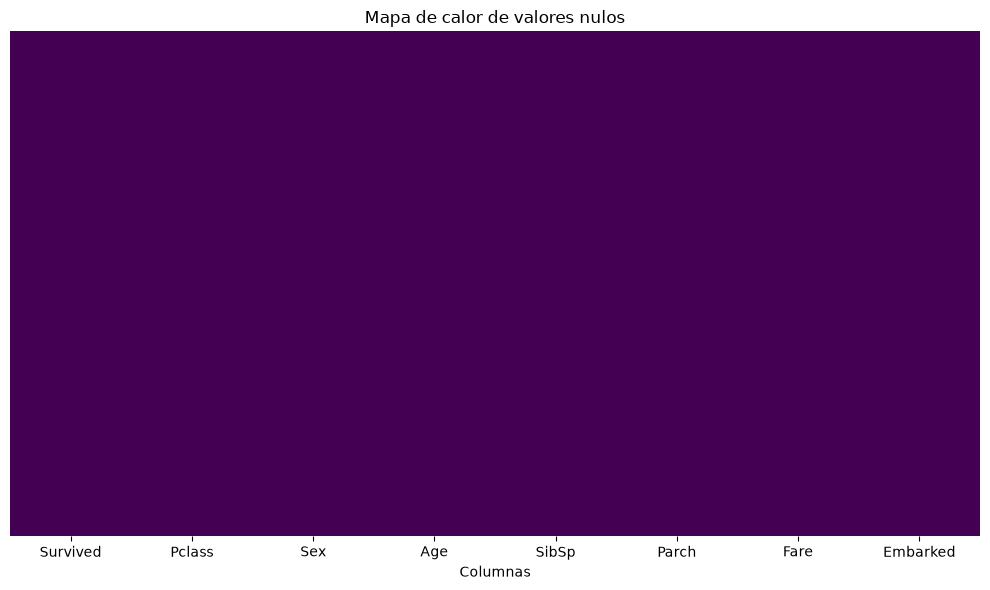

In [19]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Si aún no has cargado el dataframe:
df = pd.read_csv("data_as//titanic.csv")

# Mapa de calor de valores nulos
plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Mapa de calor de valores nulos")
plt.xlabel("Columnas")
plt.tight_layout()
plt.show()

In [3]:
porcentaje_nulos = (
    (df.isnull().mean() * 100)
    .round(2)
    .sort_values(ascending=False)
    .rename("porcentaje_nulos")
    .to_frame()
)
print(porcentaje_nulos)

          porcentaje_nulos
Survived               0.0
Pclass                 0.0
Sex                    0.0
Age                    0.0
SibSp                  0.0
Parch                  0.0
Fare                   0.0
Embarked               0.0


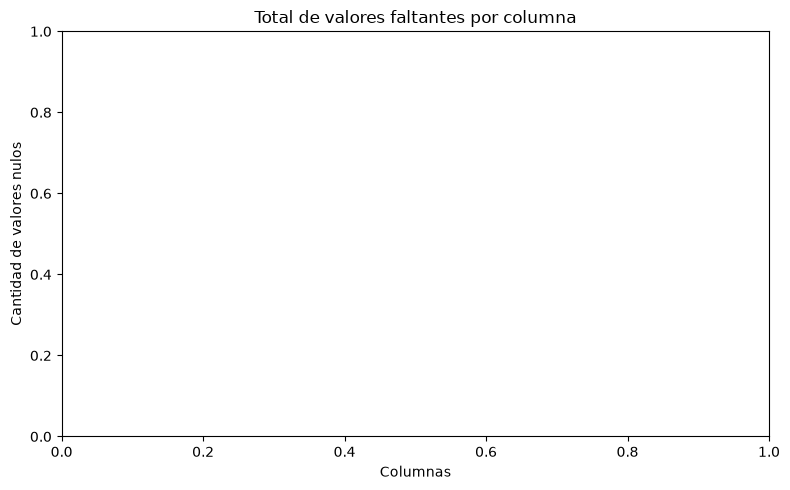

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

# Total de valores faltantes por columna (de mayor a menor)
total_nulos = df.isnull().sum().sort_values(ascending=False)

# Opcional: mostrar solo las columnas que tienen nulos
total_nulos = total_nulos[total_nulos > 0]

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=total_nulos.index, y=total_nulos.values, palette="viridis")

# Mostrar el valor encima de cada barra
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title("Total de valores faltantes por columna")
plt.xlabel("Columnas")
plt.ylabel("Cantidad de valores nulos")
plt.tight_layout()
plt.show()

In [6]:
# Calcular la mediana de la columna Age
median_age = df['Age'].median()

# Imputar los valores nulos con la mediana
df['Age'].fillna(median_age, inplace=True)

C:\Users\rinzl\AppData\Local\Temp\ipykernel_19932\686027435.py:5: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['Age'].fillna(median_age, inplace=True)


0      22.0
1      38.0
2      26.0
3      35.0
4      35.0
       ... 
886    27.0
887    19.0
888    28.0
889    26.0
890    32.0
Name: Age, Length: 891, dtype: float64

In [7]:
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [9]:
round(df.isnull().sum().sort_values(ascending = False) / len(df) * 100, 2)

Survived    0.0
Pclass      0.0
Sex         0.0
Age         0.0
SibSp       0.0
Parch       0.0
Fare        0.0
Embarked    0.0
dtype: float64

In [10]:
df.isnull().sum()

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(116)

In [ ]:
df.drop('Name', axis = 1, inplace = True)
df.drop('Ticket', axis = 1, inplace = True)
df.drop('PassengerId', axis = 1, inplace = True)

KeyError: "['Name'] not found in axis"

In [15]:
print(f"Después de limpiar df: {df.shape[0]} filas y {df.shape[1]} columnas.")

Después de limpiar df: 891 filas y 8 columnas.
